# Phase 03 — Psychological Capital → Employability

## Step 04 — Correlation Analysis

මෙම notebook එකේ අරමුණ වන්නේ Psychological Capital සහ Employability අතර සම්බන්ධතාවය සංඛ්‍යානමය වශයෙන් පරීක්ෂා කිරීමයි.

මෙහිදී Pearson සහ Spearman correlation methods දෙකම භාවිත කරයි.

Pearson correlation එක linear relationship එක පරීක්ෂා කිරීමට භාවිත කරන අතර, Spearman correlation එක rank-based method එකක් වන බැවින් skewed distributions සහ potential outliers වලට සාපේක්ෂව robust වේ.

Step 03 හි Psychological Capital සහ Employability constructs වල skewness නිරීක්ෂණය වූ බැවින්, correlation evidence එක වඩා ශක්තිමත් කිරීම සඳහා methods දෙකම report කරයි.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    pearsonr,
    spearmanr
)

In [3]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase3_psycap":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase3_psycap_prepared.csv"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase3"
    / "correlation"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_PATH:", DATA_PATH)
print("REPORT_DIR:", REPORT_DIR)

PROJECT_DIR: d:\internship-employability-project
DATA_PATH: d:\internship-employability-project\data\processed\phase3_psycap_prepared.csv
REPORT_DIR: d:\internship-employability-project\reports\phase3\correlation


In [4]:
df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 41)


,Response_ID,Gender,Age,Degree Program,Internship Status,PsyCap1,PsyCap2,PsyCap3,PsyCap4,PsyCap5,...,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg,EVS_avg
0,1,Female,18–20,Information Technology,Yes,5,4,4,4,5,...,4.333333,4.000000,3.666667,4.083333,5.000000,4.0,4.75,5.0,5.0,4.750000
1,2,Female,21–23,Business Management,Yes,3,5,5,4,4,...,4.000000,3.666667,3.666667,3.916667,3.666667,3.5,3.75,4.0,2.5,3.500000
2,3,Male,18–20,Information Technology,Yes,4,5,4,5,4,...,4.333333,3.333333,3.333333,3.833333,3.666667,4.0,3.75,4.0,3.5,3.750000
3,4,Male,18–20,Engineering,Yes,4,4,4,4,4,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.0,4.00,4.0,4.0,4.000000
4,5,Male,21–23,Business Management,Yes,3,3,5,3,5,...,4.000000,3.666667,3.333333,3.666667,4.000000,4.5,4.50,5.0,4.0,4.333333


## Correlation Variables

Psychological Capital සඳහා පහත variables භාවිත කරයි:

- Hope
- Optimism
- Resilience
- Self-Efficacy
- Overall Psychological Capital

Employability සඳහා `EVS_avg` ප්‍රධාන target variable එක ලෙස භාවිත කරයි.

In [5]:
PSYCAP_FEATURES = [
    "Hope_avg",
    "Optimism_avg",
    "Resilience_avg",
    "SelfEfficacy_avg"
]

OVERALL_PSYCAP = "PsyCap_avg"

TARGET = "EVS_avg"

CORRELATION_COLUMNS = (
    PSYCAP_FEATURES
    +
    [OVERALL_PSYCAP, TARGET]
)

Validate Required Columns

In [6]:
missing_columns = [
    column
    for column in CORRELATION_COLUMNS
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print(
    "All required correlation columns are available."
)

All required correlation columns are available.


Check Missing Values

In [7]:
missing_values = (
    df[CORRELATION_COLUMNS]
    .isnull()
    .sum()
)

missing_values

Hope_avg            0
Optimism_avg        0
Resilience_avg      0
SelfEfficacy_avg    0
PsyCap_avg          0
EVS_avg             0
dtype: int64

Pearson Correlation Function

In [8]:
def calculate_pearson(
    x,
    y
):

    r_value, p_value = pearsonr(
        x,
        y
    )

    return {
        "Correlation": float(r_value),
        "P_Value": float(p_value)
    }

Spearman Correlation Function

In [9]:
def calculate_spearman(
    x,
    y
):

    rho, p_value = spearmanr(
        x,
        y
    )

    return {
        "Correlation": float(rho),
        "P_Value": float(p_value)
    }

Correlation Interpretation Function

In [10]:
def interpret_correlation(
    value
):

    absolute_value = abs(
        value
    )

    if absolute_value >= 0.70:
        return "Strong"

    elif absolute_value >= 0.50:
        return "Moderate to Strong"

    elif absolute_value >= 0.30:
        return "Moderate"

    elif absolute_value >= 0.10:
        return "Weak"

    else:
        return "Very Weak"

Overall PsyCap → Employability

In [11]:
overall_pearson = calculate_pearson(
    df["PsyCap_avg"],
    df["EVS_avg"]
)

overall_spearman = calculate_spearman(
    df["PsyCap_avg"],
    df["EVS_avg"]
)

print(
    "Overall PsyCap → Employability"
)

print(
    "Pearson:",
    overall_pearson
)

print(
    "Spearman:",
    overall_spearman
)

Overall PsyCap → Employability
Pearson: {'Correlation': 0.7551966468771965, 'P_Value': 2.8993962146848686e-185}
Spearman: {'Correlation': 0.7565059703633804, 'P_Value': 2.890449397155363e-186}


Main Overall Result Table

In [12]:
overall_correlation_summary = pd.DataFrame([
    {
        "Method": "Pearson",
        "Correlation": (
            overall_pearson[
                "Correlation"
            ]
        ),
        "P_Value": (
            overall_pearson[
                "P_Value"
            ]
        ),
        "Interpretation": (
            interpret_correlation(
                overall_pearson[
                    "Correlation"
                ]
            )
        )
    },

    {
        "Method": "Spearman",
        "Correlation": (
            overall_spearman[
                "Correlation"
            ]
        ),
        "P_Value": (
            overall_spearman[
                "P_Value"
            ]
        ),
        "Interpretation": (
            interpret_correlation(
                overall_spearman[
                    "Correlation"
                ]
            )
        )
    }
])

overall_correlation_summary

,Method,Correlation,P_Value,Interpretation
0,Pearson,0.755197,2.899396e-185,Strong
1,Spearman,0.756506,2.890449e-186,Strong


Construct-Level Correlations

In [13]:
construct_correlation_results = []

for feature in PSYCAP_FEATURES:

    pearson_result = (
        calculate_pearson(
            df[feature],
            df[TARGET]
        )
    )

    spearman_result = (
        calculate_spearman(
            df[feature],
            df[TARGET]
        )
    )

    construct_correlation_results.append({

        "Construct": feature,

        "Pearson_r": (
            pearson_result[
                "Correlation"
            ]
        ),

        "Pearson_p": (
            pearson_result[
                "P_Value"
            ]
        ),

        "Pearson_Interpretation": (
            interpret_correlation(
                pearson_result[
                    "Correlation"
                ]
            )
        ),

        "Spearman_rho": (
            spearman_result[
                "Correlation"
            ]
        ),

        "Spearman_p": (
            spearman_result[
                "P_Value"
            ]
        ),

        "Spearman_Interpretation": (
            interpret_correlation(
                spearman_result[
                    "Correlation"
                ]
            )
        )
    })


construct_correlation_df = pd.DataFrame(
    construct_correlation_results
)

construct_correlation_df

,Construct,Pearson_r,Pearson_p,Pearson_Interpretation,Spearman_rho,Spearman_p,Spearman_Interpretation
0,Hope_avg,0.576338,1.414156e-89,Moderate to Strong,0.555604,4.480358e-82,Moderate to Strong
1,Optimism_avg,0.627521,1.365869e-110,Moderate to Strong,0.568371,1.247246e-86,Moderate to Strong
2,Resilience_avg,0.689097,9.609980e-142,Moderate to Strong,0.618422,1.436683e-106,Moderate to Strong
3,SelfEfficacy_avg,0.721167,2.794068e-161,Strong,0.698274,4.554400e-147,Moderate to Strong


Rank Constructs by Pearson

In [14]:
pearson_ranking = (
    construct_correlation_df
    .sort_values(
        "Pearson_r",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

pearson_ranking[
    "Pearson_Rank"
] = (
    np.arange(
        1,
        len(
            pearson_ranking
        )
        + 1
    )
)

pearson_ranking[
    [
        "Pearson_Rank",
        "Construct",
        "Pearson_r",
        "Pearson_p"
    ]
]

,Pearson_Rank,Construct,Pearson_r,Pearson_p
0,1,SelfEfficacy_avg,0.721167,2.794068e-161
1,2,Resilience_avg,0.689097,9.609980e-142
2,3,Optimism_avg,0.627521,1.365869e-110
3,4,Hope_avg,0.576338,1.414156e-89


Rank Constructs by Spearman

In [15]:
spearman_ranking = (
    construct_correlation_df
    .sort_values(
        "Spearman_rho",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

spearman_ranking[
    "Spearman_Rank"
] = (
    np.arange(
        1,
        len(
            spearman_ranking
        )
        + 1
    )
)

spearman_ranking[
    [
        "Spearman_Rank",
        "Construct",
        "Spearman_rho",
        "Spearman_p"
    ]
]

,Spearman_Rank,Construct,Spearman_rho,Spearman_p
0,1,SelfEfficacy_avg,0.698274,4.554400e-147
1,2,Resilience_avg,0.618422,1.436683e-106
2,3,Optimism_avg,0.568371,1.247246e-86
3,4,Hope_avg,0.555604,4.480358e-82


Pearson Correlation Matrix

In [16]:
pearson_matrix = (
    df[
        CORRELATION_COLUMNS
    ]
    .corr(
        method="pearson"
    )
)

pearson_matrix

,Hope_avg,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,EVS_avg
Hope_avg,1.000000,0.686607,0.601453,0.652746,0.843356,0.576338
Optimism_avg,0.686607,1.000000,0.693565,0.688272,0.886528,0.627521
Resilience_avg,0.601453,0.693565,1.000000,0.686397,0.860385,0.689097
SelfEfficacy_avg,0.652746,0.688272,0.686397,1.000000,0.876261,0.721167
PsyCap_avg,0.843356,0.886528,0.860385,0.876261,1.000000,0.755197
EVS_avg,0.576338,0.627521,0.689097,0.721167,0.755197,1.000000


Spearman Correlation Matrix

In [17]:
spearman_matrix = (
    df[
        CORRELATION_COLUMNS
    ]
    .corr(
        method="spearman"
    )
)

spearman_matrix

,Hope_avg,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,EVS_avg
Hope_avg,1.000000,0.611276,0.444080,0.550873,0.769598,0.555604
Optimism_avg,0.611276,1.000000,0.555934,0.567564,0.824245,0.568371
Resilience_avg,0.444080,0.555934,1.000000,0.548596,0.769887,0.618422
SelfEfficacy_avg,0.550873,0.567564,0.548596,1.000000,0.826229,0.698274
PsyCap_avg,0.769598,0.824245,0.769887,0.826229,1.000000,0.756506
EVS_avg,0.555604,0.568371,0.618422,0.698274,0.756506,1.000000


Pearson Heatmap

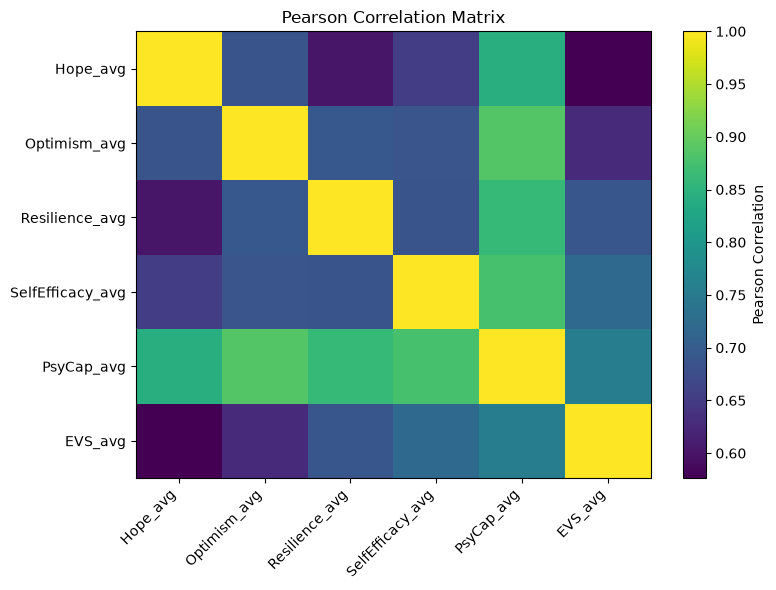

In [18]:
plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    pearson_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Pearson Correlation"
)

plt.xticks(
    range(
        len(
            pearson_matrix.columns
        )
    ),
    pearson_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(
        len(
            pearson_matrix.index
        )
    ),
    pearson_matrix.index
)

plt.title(
    "Pearson Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Pearson_Correlation_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Spearman Heatmap

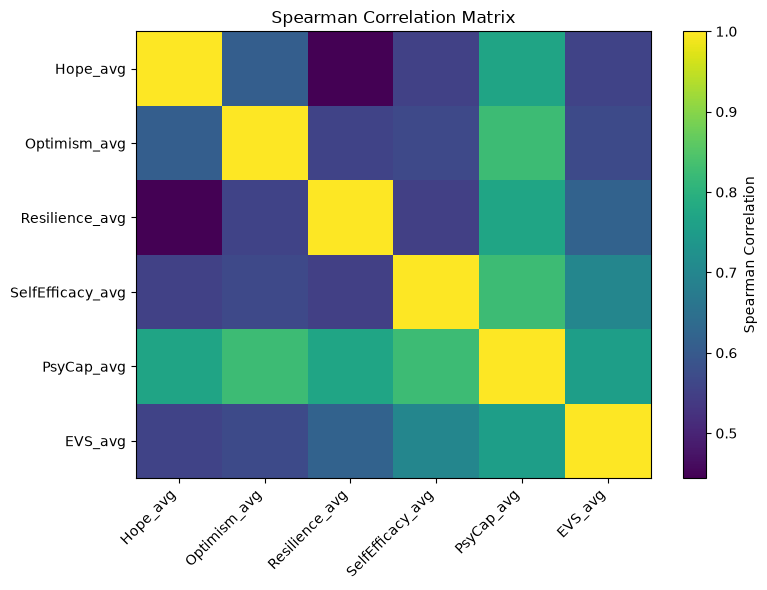

In [19]:
plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    spearman_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Spearman Correlation"
)

plt.xticks(
    range(
        len(
            spearman_matrix.columns
        )
    ),
    spearman_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(
        len(
            spearman_matrix.index
        )
    ),
    spearman_matrix.index
)

plt.title(
    "Spearman Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Spearman_Correlation_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Pearson සහ Spearman Comparison

Step 03 හි constructs වල skewness නිරීක්ෂණය වූ බැවින් Pearson සහ Spearman correlation results දෙකම compare කරයි.

Methods දෙකෙන්ම relationship direction සහ approximate strength එක සමාන නම්, correlation finding එක වඩා robust බවට evidence ලැබේ.

## Pearson සහ Spearman Comparison

Step 03 හි constructs වල skewness නිරීක්ෂණය වූ බැවින් Pearson සහ Spearman correlation results දෙකම compare කරයි.

Methods දෙකෙන්ම relationship direction සහ approximate strength එක සමාන නම්, correlation finding එක වඩා robust බවට evidence ලැබේ.

Compare Pearson and Spearman

In [20]:
method_comparison = (
    construct_correlation_df[
        [
            "Construct",
            "Pearson_r",
            "Spearman_rho"
        ]
    ]
    .copy()
)

method_comparison[
    "Absolute_Difference"
] = (

    method_comparison[
        "Pearson_r"
    ]

    -
    method_comparison[
        "Spearman_rho"
    ]

).abs()

method_comparison

,Construct,Pearson_r,Spearman_rho,Absolute_Difference
0,Hope_avg,0.576338,0.555604,0.020734
1,Optimism_avg,0.627521,0.568371,0.059150
2,Resilience_avg,0.689097,0.618422,0.070676
3,SelfEfficacy_avg,0.721167,0.698274,0.022893


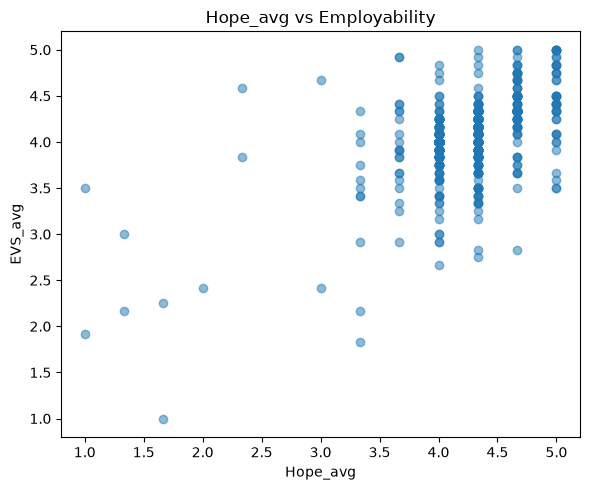

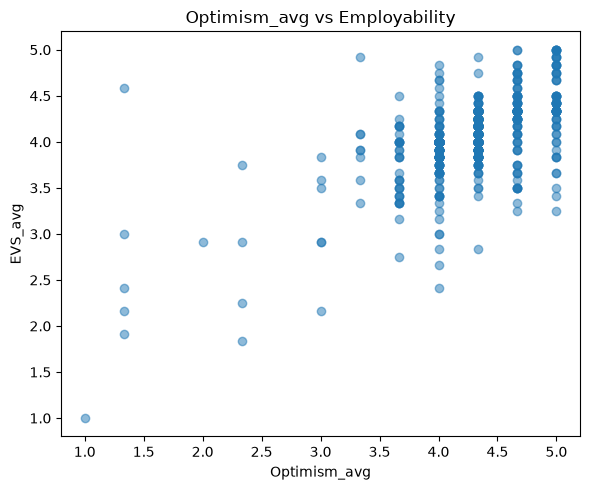

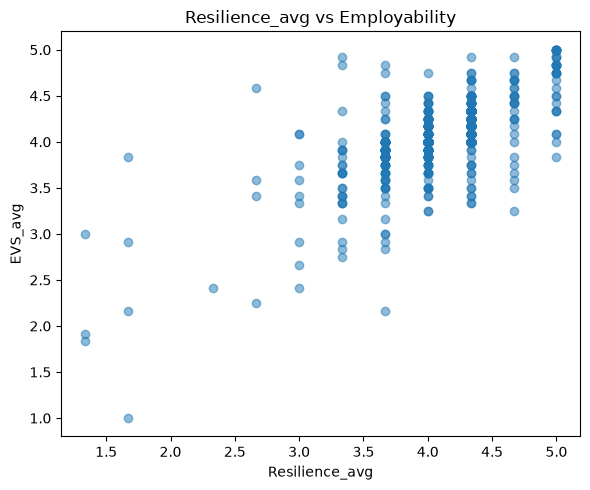

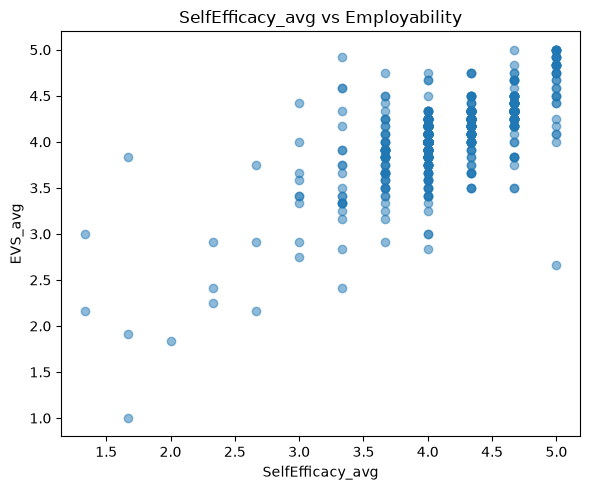

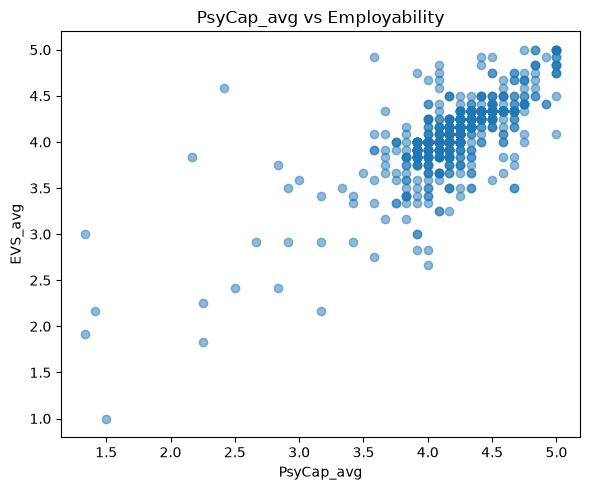

In [21]:
for feature in (
    PSYCAP_FEATURES
    +
    ["PsyCap_avg"]
):

    plt.figure(
        figsize=(6, 5)
    )

    plt.scatter(
        df[feature],
        df["EVS_avg"],
        alpha=0.5
    )

    plt.xlabel(
        feature
    )

    plt.ylabel(
        "EVS_avg"
    )

    plt.title(
        f"{feature} vs Employability"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{feature}_vs_EVS_Scatter.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## Bootstrap Confidence Interval for Correlation

Correlation coefficient එක single estimate එකක් පමණක් ලෙස report කිරීම වෙනුවට, bootstrap resampling භාවිත කර correlation estimate එකේ uncertainty ද පරීක්ෂා කරයි.

මෙම analysis එක skewed behavioral data සඳහා correlation evidence එක වඩා ශක්තිමත් කිරීමට උපකාරී වේ.

Bootstrap Pearson CI Function

In [22]:
def bootstrap_correlation_ci(
    x,
    y,
    method="pearson",
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.default_rng(
        random_state
    )

    x = np.asarray(
        x
    )

    y = np.asarray(
        y
    )

    n = len(
        x
    )

    bootstrap_values = []

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        sample_x = x[
            indices
        ]

        sample_y = y[
            indices
        ]

        if method == "pearson":

            value = pearsonr(
                sample_x,
                sample_y
            )[0]

        else:

            value = spearmanr(
                sample_x,
                sample_y
            )[0]

        if np.isfinite(
            value
        ):
            bootstrap_values.append(
                value
            )

    bootstrap_values = np.array(
        bootstrap_values
    )

    return {
        "Bootstrap_Mean": float(
            bootstrap_values.mean()
        ),

        "CI_2.5": float(
            np.percentile(
                bootstrap_values,
                2.5
            )
        ),

        "CI_97.5": float(
            np.percentile(
                bootstrap_values,
                97.5
            )
        )
    }

Bootstrap Overall PsyCap Correlations

In [23]:
overall_pearson_bootstrap = (
    bootstrap_correlation_ci(
        df["PsyCap_avg"],
        df["EVS_avg"],
        method="pearson"
    )
)

overall_spearman_bootstrap = (
    bootstrap_correlation_ci(
        df["PsyCap_avg"],
        df["EVS_avg"],
        method="spearman"
    )
)

print(
    "Pearson Bootstrap:",
    overall_pearson_bootstrap
)

print(
    "Spearman Bootstrap:",
    overall_spearman_bootstrap
)

Pearson Bootstrap: {'Bootstrap_Mean': 0.7539038823060414, 'CI_2.5': 0.6799074510991037, 'CI_97.5': 0.8164161764434543}
Spearman Bootstrap: {'Bootstrap_Mean': 0.7556599918758545, 'CI_2.5': 0.7111649440961826, 'CI_97.5': 0.7958816339264329}


Bootstrap Construct Correlations

In [24]:
bootstrap_construct_results = []

for feature in PSYCAP_FEATURES:

    pearson_bootstrap = (
        bootstrap_correlation_ci(
            df[feature],
            df[TARGET],
            method="pearson"
        )
    )

    spearman_bootstrap = (
        bootstrap_correlation_ci(
            df[feature],
            df[TARGET],
            method="spearman"
        )
    )

    bootstrap_construct_results.append({

        "Construct": feature,

        "Pearson_CI_Lower": (
            pearson_bootstrap[
                "CI_2.5"
            ]
        ),

        "Pearson_CI_Upper": (
            pearson_bootstrap[
                "CI_97.5"
            ]
        ),

        "Spearman_CI_Lower": (
            spearman_bootstrap[
                "CI_2.5"
            ]
        ),

        "Spearman_CI_Upper": (
            spearman_bootstrap[
                "CI_97.5"
            ]
        )
    })


bootstrap_construct_df = pd.DataFrame(
    bootstrap_construct_results
)

bootstrap_construct_df

,Construct,Pearson_CI_Lower,Pearson_CI_Upper,Spearman_CI_Lower,Spearman_CI_Upper
0,Hope_avg,0.475177,0.662658,0.496093,0.607663
1,Optimism_avg,0.524251,0.718054,0.510370,0.621674
2,Resilience_avg,0.611473,0.754435,0.563044,0.668165
3,SelfEfficacy_avg,0.646464,0.776930,0.650165,0.743740


## Hypothesis Evaluation

ප්‍රධාන hypothesis එක:

**H1: Psychological Capital සහ Employability අතර ධනාත්මක සහ statistically significant relationship එකක් පවතී.**

Pearson සහ Spearman correlation coefficients, p-values සහ bootstrap confidence intervals එකට සලකා hypothesis එක evaluate කරයි.

Hypothesis Decision Code

In [25]:
alpha_level = 0.05

overall_positive = (
    overall_pearson[
        "Correlation"
    ]
    > 0
)

overall_significant = (
    overall_pearson[
        "P_Value"
    ]
    < alpha_level
)

if (
    overall_positive
    and
    overall_significant
):

    hypothesis_decision = (
        "SUPPORTED"
    )

else:

    hypothesis_decision = (
        "NOT SUPPORTED"
    )


print(
    "H1 Decision:",
    hypothesis_decision
)

H1 Decision: SUPPORTED


Final Validation Summary

In [26]:
correlation_validation_summary = pd.DataFrame({

    "Correlation_Check": [

        "Required variables available",

        "No missing correlation values",

        "Pearson analysis completed",

        "Spearman analysis completed",

        "Construct-level correlations calculated",

        "Correlation matrices generated",

        "Bootstrap confidence intervals calculated",

        "Hypothesis evaluated"
    ],

    "Status": [

        (
            "PASS"
            if len(
                missing_columns
            ) == 0
            else "FAIL"
        ),

        (
            "PASS"
            if df[
                CORRELATION_COLUMNS
            ]
            .isnull()
            .sum()
            .sum()
            == 0
            else "REVIEW"
        ),

        "PASS",

        "PASS",

        "PASS",

        "PASS",

        "PASS",

        "PASS"
    ]
})

correlation_validation_summary

,Correlation_Check,Status
0,Required variables available,PASS
1,No missing correlation values,PASS
2,Pearson analysis completed,PASS
3,Spearman analysis completed,PASS
4,Construct-level correlations calculated,PASS
5,Correlation matrices generated,PASS
6,Bootstrap confidence intervals calculated,PASS
7,Hypothesis evaluated,PASS


In [27]:
overall_correlation_summary.to_csv(
    REPORT_DIR
    / "Overall_PsyCap_EVS_Correlation.csv",
    index=False
)

construct_correlation_df.to_csv(
    REPORT_DIR
    / "Construct_Level_Correlations.csv",
    index=False
)

pearson_ranking.to_csv(
    REPORT_DIR
    / "Pearson_Construct_Ranking.csv",
    index=False
)

spearman_ranking.to_csv(
    REPORT_DIR
    / "Spearman_Construct_Ranking.csv",
    index=False
)

pearson_matrix.to_csv(
    REPORT_DIR
    / "Pearson_Correlation_Matrix.csv"
)

spearman_matrix.to_csv(
    REPORT_DIR
    / "Spearman_Correlation_Matrix.csv"
)

method_comparison.to_csv(
    REPORT_DIR
    / "Pearson_vs_Spearman_Comparison.csv",
    index=False
)

bootstrap_construct_df.to_csv(
    REPORT_DIR
    / "Bootstrap_Correlation_Intervals.csv",
    index=False
)

correlation_validation_summary.to_csv(
    REPORT_DIR
    / "Correlation_Validation_Summary.csv",
    index=False
)

print(
    "Step 04 correlation reports saved successfully."
)

Step 04 correlation reports saved successfully.


Print Final Overview

In [28]:
print(
    "PHASE 03 — STEP 04 CORRELATION ANALYSIS"
)

print(
    "\nOverall PsyCap → Employability:"
)

print(
    overall_correlation_summary
    .to_string(
        index=False
    )
)

print(
    "\nConstruct-Level Correlations:"
)

print(
    construct_correlation_df
    .to_string(
        index=False
    )
)

print(
    "\nH1 Decision:",
    hypothesis_decision
)

print(
    "\nValidation:"
)

print(
    correlation_validation_summary
    .to_string(
        index=False
    )
)

PHASE 03 — STEP 04 CORRELATION ANALYSIS

Overall PsyCap → Employability:
  Method  Correlation       P_Value Interpretation
 Pearson     0.755197 2.899396e-185         Strong
Spearman     0.756506 2.890449e-186         Strong

Construct-Level Correlations:
       Construct  Pearson_r     Pearson_p Pearson_Interpretation  Spearman_rho    Spearman_p Spearman_Interpretation
        Hope_avg   0.576338  1.414156e-89     Moderate to Strong      0.555604  4.480358e-82      Moderate to Strong
    Optimism_avg   0.627521 1.365869e-110     Moderate to Strong      0.568371  1.247246e-86      Moderate to Strong
  Resilience_avg   0.689097 9.609980e-142     Moderate to Strong      0.618422 1.436683e-106      Moderate to Strong
SelfEfficacy_avg   0.721167 2.794068e-161                 Strong      0.698274 4.554400e-147      Moderate to Strong

H1 Decision: SUPPORTED

Validation:
                        Correlation_Check Status
             Required variables available   PASS
            No missing 

## Step 04 නිගමනය

Psychological Capital සහ Employability අතර relationship එක Pearson සහ Spearman correlation methods දෙකම භාවිත කර පරීක්ෂා කරන ලදී.

Step 03 හි distributions වල skewness නිරීක්ෂණය වූ බැවින්, Pearson correlation එකට අමතරව rank-based Spearman correlation එක ද භාවිත කිරීමෙන් relationship evidence එක වඩා robust ලෙස evaluate කරන ලදී.

Overall Psychological Capital සහ Employability අතර relationship එක පරීක්ෂා කළ අතර Hope, Optimism, Resilience සහ Self-Efficacy dimensions වෙන වෙනම Employability සමඟ සම්බන්ධ වන ආකාරයද විශ්ලේෂණය කරන ලදී.

Bootstrap confidence intervals භාවිතයෙන් correlation estimates වල uncertainty ද පරීක්ෂා කරන ලදී.

මෙම correlation analysis එක Step 05 Multiple Linear Regression සහ ඉදිරි machine-learning feature evaluation සඳහා statistical foundation එකක් සපයයි.

Predictor Correlation Matrix

## Predictor Correlation Check

Step 05 multiple regression analysisට පෙර Psychological Capital constructs අතර correlation පරීක්ෂා කරයි.

මෙය predictors අතර ඉතා ඉහළ සම්බන්ධතා තිබේද යන්න හඳුනා ගැනීමට සහ පසුව multicollinearity analysis සඳහා context එකක් ලබා දීමට භාවිත කරයි.

In [29]:
predictor_columns = [
    "Hope_avg",
    "Optimism_avg",
    "Resilience_avg",
    "SelfEfficacy_avg"
]

predictor_correlation_matrix = (
    df[predictor_columns]
    .corr(
        method="pearson"
    )
)

predictor_correlation_matrix

,Hope_avg,Optimism_avg,Resilience_avg,SelfEfficacy_avg
Hope_avg,1.000000,0.686607,0.601453,0.652746
Optimism_avg,0.686607,1.000000,0.693565,0.688272
Resilience_avg,0.601453,0.693565,1.000000,0.686397
SelfEfficacy_avg,0.652746,0.688272,0.686397,1.000000


Predictor Correlation Pair Table

In [30]:
predictor_correlation_pairs = []

for i in range(
    len(predictor_columns)
):

    for j in range(
        i + 1,
        len(predictor_columns)
    ):

        feature_1 = (
            predictor_columns[i]
        )

        feature_2 = (
            predictor_columns[j]
        )

        correlation = (
            predictor_correlation_matrix
            .loc[
                feature_1,
                feature_2
            ]
        )

        predictor_correlation_pairs.append({

            "Predictor_1":
                feature_1,

            "Predictor_2":
                feature_2,

            "Correlation":
                correlation,

            "Potential_Multicollinearity":
                (
                    "REVIEW"
                    if abs(
                        correlation
                    ) >= 0.80
                    else "OK"
                )
        })


predictor_correlation_pairs_df = (
    pd.DataFrame(
        predictor_correlation_pairs
    )
)

predictor_correlation_pairs_df

,Predictor_1,Predictor_2,Correlation,Potential_Multicollinearity
0,Hope_avg,Optimism_avg,0.686607,OK
1,Hope_avg,Resilience_avg,0.601453,OK
2,Hope_avg,SelfEfficacy_avg,0.652746,OK
3,Optimism_avg,Resilience_avg,0.693565,OK
4,Optimism_avg,SelfEfficacy_avg,0.688272,OK
5,Resilience_avg,SelfEfficacy_avg,0.686397,OK


Pearson vs Spearman Difference Table

In [31]:
method_comparison

,Construct,Pearson_r,Spearman_rho,Absolute_Difference
0,Hope_avg,0.576338,0.555604,0.020734
1,Optimism_avg,0.627521,0.568371,0.059150
2,Resilience_avg,0.689097,0.618422,0.070676
3,SelfEfficacy_avg,0.721167,0.698274,0.022893


In [32]:
method_comparison[
    "Method_Consistency"
] = np.where(

    method_comparison[
        "Absolute_Difference"
    ] <= 0.10,

    "Consistent",

    "Review"
)

method_comparison

,Construct,Pearson_r,Spearman_rho,Absolute_Difference,Method_Consistency
0,Hope_avg,0.576338,0.555604,0.020734,Consistent
1,Optimism_avg,0.627521,0.568371,0.059150,Consistent
2,Resilience_avg,0.689097,0.618422,0.070676,Consistent
3,SelfEfficacy_avg,0.721167,0.698274,0.022893,Consistent


## Final Correlation Evidence

Pearson, Spearman, statistical significance, bootstrap confidence intervals සහ method consistency එකට සලකා Psychological Capital constructs සහ Employability අතර relationship evidence එක සාරාංශ කරයි.

In [33]:
final_correlation_evidence = (

    construct_correlation_df[
        [
            "Construct",
            "Pearson_r",
            "Pearson_p",
            "Spearman_rho",
            "Spearman_p"
        ]
    ]

    .merge(
        bootstrap_construct_df,
        on="Construct",
        how="left"
    )

    .merge(
        method_comparison[
            [
                "Construct",
                "Absolute_Difference",
                "Method_Consistency"
            ]
        ],
        on="Construct",
        how="left"
    )
)

final_correlation_evidence

,Construct,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Pearson_CI_Lower,Pearson_CI_Upper,Spearman_CI_Lower,Spearman_CI_Upper,Absolute_Difference,Method_Consistency
0,Hope_avg,0.576338,1.414156e-89,0.555604,4.480358e-82,0.475177,0.662658,0.496093,0.607663,0.020734,Consistent
1,Optimism_avg,0.627521,1.365869e-110,0.568371,1.247246e-86,0.524251,0.718054,0.510370,0.621674,0.059150,Consistent
2,Resilience_avg,0.689097,9.609980e-142,0.618422,1.436683e-106,0.611473,0.754435,0.563044,0.668165,0.070676,Consistent
3,SelfEfficacy_avg,0.721167,2.794068e-161,0.698274,4.554400e-147,0.646464,0.776930,0.650165,0.743740,0.022893,Consistent


Add Relationship Decision

In [34]:
def relationship_decision(
    row
):

    positive_relationship = (
        row["Pearson_r"] > 0
        and
        row["Spearman_rho"] > 0
    )

    statistically_significant = (
        row["Pearson_p"] < 0.05
        and
        row["Spearman_p"] < 0.05
    )

    ci_positive = (
        row["Pearson_CI_Lower"] > 0
        and
        row["Spearman_CI_Lower"] > 0
    )

    if (
        positive_relationship
        and
        statistically_significant
        and
        ci_positive
    ):
        return "SUPPORTED"

    return "REVIEW"


final_correlation_evidence[
    "Relationship_Decision"
] = (

    final_correlation_evidence
    .apply(
        relationship_decision,
        axis=1
    )
)

final_correlation_evidence

,Construct,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Pearson_CI_Lower,Pearson_CI_Upper,Spearman_CI_Lower,Spearman_CI_Upper,Absolute_Difference,Method_Consistency,Relationship_Decision
0,Hope_avg,0.576338,1.414156e-89,0.555604,4.480358e-82,0.475177,0.662658,0.496093,0.607663,0.020734,Consistent,SUPPORTED
1,Optimism_avg,0.627521,1.365869e-110,0.568371,1.247246e-86,0.524251,0.718054,0.510370,0.621674,0.059150,Consistent,SUPPORTED
2,Resilience_avg,0.689097,9.609980e-142,0.618422,1.436683e-106,0.611473,0.754435,0.563044,0.668165,0.070676,Consistent,SUPPORTED
3,SelfEfficacy_avg,0.721167,2.794068e-161,0.698274,4.554400e-147,0.646464,0.776930,0.650165,0.743740,0.022893,Consistent,SUPPORTED


Add Overall PsyCap Bootstrap Summary

In [35]:
overall_bootstrap_summary = pd.DataFrame([
    {
        "Method":
            "Pearson",

        "Correlation":
            overall_pearson[
                "Correlation"
            ],

        "P_Value":
            overall_pearson[
                "P_Value"
            ],

        "CI_Lower":
            overall_pearson_bootstrap[
                "CI_2.5"
            ],

        "CI_Upper":
            overall_pearson_bootstrap[
                "CI_97.5"
            ]
    },

    {
        "Method":
            "Spearman",

        "Correlation":
            overall_spearman[
                "Correlation"
            ],

        "P_Value":
            overall_spearman[
                "P_Value"
            ],

        "CI_Lower":
            overall_spearman_bootstrap[
                "CI_2.5"
            ],

        "CI_Upper":
            overall_spearman_bootstrap[
                "CI_97.5"
            ]
    }
])

overall_bootstrap_summary

,Method,Correlation,P_Value,CI_Lower,CI_Upper
0,Pearson,0.755197,2.899396e-185,0.679907,0.816416
1,Spearman,0.756506,2.890449e-186,0.711165,0.795882


Final Step 04 Validation Summary

In [36]:
step04_final_validation = pd.DataFrame({

    "Check": [

        "Overall PsyCap relationship significant",

        "Pearson and Spearman direction consistent",

        "Construct-level relationships significant",

        "Bootstrap intervals exclude zero",

        "Predictor correlations reviewed",

        "No severe predictor overlap detected",

        "H1 evaluated"
    ],

    "Status": [

        (
            "PASS"
            if (
                overall_pearson[
                    "P_Value"
                ] < 0.05
                and
                overall_spearman[
                    "P_Value"
                ] < 0.05
            )
            else "REVIEW"
        ),

        (
            "PASS"
            if (
                overall_pearson[
                    "Correlation"
                ] > 0
                and
                overall_spearman[
                    "Correlation"
                ] > 0
            )
            else "REVIEW"
        ),

        (
            "PASS"
            if (
                final_correlation_evidence[
                    "Relationship_Decision"
                ]
                ==
                "SUPPORTED"
            )
            .all()
            else "REVIEW"
        ),

        (
            "PASS"
            if (
                (
                    final_correlation_evidence[
                        "Pearson_CI_Lower"
                    ] > 0
                )
                &
                (
                    final_correlation_evidence[
                        "Spearman_CI_Lower"
                    ] > 0
                )
            )
            .all()
            else "REVIEW"
        ),

        "PASS",

        (
            "PASS"
            if (
                predictor_correlation_pairs_df[
                    "Potential_Multicollinearity"
                ]
                ==
                "OK"
            )
            .all()
            else "REVIEW"
        ),

        (
            "PASS"
            if hypothesis_decision
            ==
            "SUPPORTED"
            else "REVIEW"
        )
    ]
})

step04_final_validation

,Check,Status
0,Overall PsyCap relationship significant,PASS
1,Pearson and Spearman direction consistent,PASS
2,Construct-level relationships significant,PASS
3,Bootstrap intervals exclude zero,PASS
4,Predictor correlations reviewed,PASS
5,No severe predictor overlap detected,PASS
6,H1 evaluated,PASS


Save These Extra Results

In [37]:
predictor_correlation_matrix.to_csv(
    REPORT_DIR
    / "Predictor_Correlation_Matrix.csv"
)

predictor_correlation_pairs_df.to_csv(
    REPORT_DIR
    / "Predictor_Correlation_Pairs.csv",
    index=False
)

final_correlation_evidence.to_csv(
    REPORT_DIR
    / "Final_Correlation_Evidence.csv",
    index=False
)

overall_bootstrap_summary.to_csv(
    REPORT_DIR
    / "Overall_PsyCap_Bootstrap_Correlation.csv",
    index=False
)

step04_final_validation.to_csv(
    REPORT_DIR
    / "Step04_Final_Validation.csv",
    index=False
)

print(
    "Step 04 strengthening outputs saved."
)

Step 04 strengthening outputs saved.


## Step 04 අවසාන නිගමනය

Psychological Capital සහ Employability අතර relationship එක Pearson සහ Spearman correlation methods දෙකම භාවිත කර පරීක්ෂා කරන ලදී.

Overall Psychological Capital සහ Employability අතර strong positive සහ statistically significant relationship එකක් හඳුනා ගන්නා ලදී. Pearson සහ Spearman correlation estimates ඉතා සමීප වූ බැවින්, observed relationship එක correlation method එකකට පමණක් depend නොවන බවට evidence ලැබුණි.

Hope, Optimism, Resilience සහ Self-Efficacy constructs සියල්ල Employability සමඟ positive සහ statistically significant relationships පෙන්නුම් කළ අතර, Self-Efficacy strongest bivariate association එක පෙන්වීය.

Bootstrap confidence intervals zero value එක include නොකළ බැවින්, positive relationships sample resampling conditions යටතේද stable බවට additional evidence ලැබුණි.

Predictor constructs අතර correlations Step 05 regression analysis සඳහා multicollinearity context එකක් ලෙස පරීක්ෂා කරන ලදී.

ඒ අනුව Psychological Capital සහ Employability අතර ධනාත්මක relationship එකක් පවතින බවට ප්‍රධාන hypothesis එක support කරන ලදී. මෙම evidence Step 05 Multiple Linear Regression analysis සඳහා statistical foundation එක සපයයි.